In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch import optim
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import matplotlib.pyplot as plt
from pathlib import Path

from denoiser_network import denoiser, denoiser_dataset

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
female_faces = Path(r"C:\Users\Elena\.cache\kagglehub\datasets\axondata\nist-dataset-3m-unique-biometric-faces\versions\1\AxonLabs_NIST_samples\Female")

ppl_images = {}
for person_folder in sorted(female_faces.iterdir()):
    imgs = [f for f in person_folder.rglob("*")]
    ppl_images[person_folder.name] = imgs

print(f"number of people in dataset: {len(ppl_images)}")


number of people in dataset: 29


In [13]:
N = 29
bs = 10
training_percentage = 0.8
n_training = int(N*training_percentage)
n_test = N - n_training
training_epochs = 100
learning_rate = 0.001

In [15]:

ppl = sorted(ppl_images)
np.random.shuffle(ppl)
train_ppl, test_ppl = ppl[:n_training], ppl[n_training:]

train_files = [f for p in train_ppl for f in ppl_images[p]]
test_files  = [f for p in test_ppl  for f in ppl_images[p]]

training_loader = DataLoader(denoiser_dataset(train_files), batch_size=bs, shuffle=True)
test_loader = DataLoader(denoiser_dataset(test_files), batch_size=n_test, shuffle=False)

In [16]:
model = denoiser()
loss = nn.L1Loss()
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-2)
lol = torch.rand((2, 3, 128, 128))
latent, denoised = model(lol)

print(latent.shape, denoised.shape)

torch.Size([2, 256, 16, 16]) torch.Size([2, 3, 128, 128])


In [17]:
loss_per_epoch = []

for epoch in range(training_epochs):
    print(f"Epoch [{epoch + 1}/{training_epochs}]")
    for batch_index, (data, targets) in enumerate(tqdm(iter(training_loader))):
        # Move data and targets to the device (GPU/CPU)
        data = data.to(device)
        targets = targets.to(device)

        # Forward pass: compute the model output
        latent, denoised = model(data)
        loss_ = loss(denoised, targets)
        loss_per_epoch.append(loss_.detach())
        
        # Backward pass: compute the gradients
        optimizer.zero_grad()
        loss_.backward()

        # Optimization step: update the model parameters
        optimizer.step()
    

Epoch [1/100]


100%|██████████| 7/7 [00:03<00:00,  2.04it/s]


Epoch [2/100]


100%|██████████| 7/7 [00:03<00:00,  2.16it/s]


Epoch [3/100]


100%|██████████| 7/7 [00:04<00:00,  1.66it/s]


... (190 outputs left out)

Epoch [99/100]


100%|██████████| 7/7 [00:05<00:00,  1.24it/s]


Epoch [100/100]


100%|██████████| 7/7 [00:06<00:00,  1.14it/s]


In [18]:
loss_per_epoch = np.array(loss_per_epoch)
loss_per_epoch = loss_per_epoch.reshape(training_epochs, 7)
print(loss_per_epoch.shape)

(100, 7)


[0.190348   0.10394394 0.09010904 0.07486087 0.06330623 0.05655829
 0.04902832 0.04441166 0.04266815 0.03904024 0.03918312 0.04198337
 0.04086199 0.03790411 0.03492146 0.03320602 0.03206515 0.03199093
 0.03130414 0.03151086 0.03111211 0.03014912 0.02995117 0.02993147
 0.02893805 0.02885257 0.02830265 0.02818968 0.02738309 0.02730825
 0.02857393 0.0270978  0.02661459 0.02619855 0.02612735 0.02640677
 0.0264937  0.02676687 0.02591303 0.02618532 0.02643926 0.02630978
 0.02613265 0.02542081 0.02496112 0.02475036 0.02453664 0.02469501
 0.02466015 0.02420481 0.02423311 0.02379846 0.02373558 0.02416831
 0.02398824 0.0244712  0.02331975 0.02398451 0.02532878 0.02518858
 0.02526155 0.02508906 0.02470862 0.0236841  0.02381942 0.02360093
 0.02317786 0.02411841 0.02358468 0.02302897 0.02270706 0.02249921
 0.02283583 0.02378416 0.02416512 0.02383825 0.02323149 0.02386868
 0.02302619 0.0228376  0.02284269 0.02289937 0.02286501 0.02312831
 0.02382949 0.02405896 0.02335799 0.02304133 0.02314    0.0228

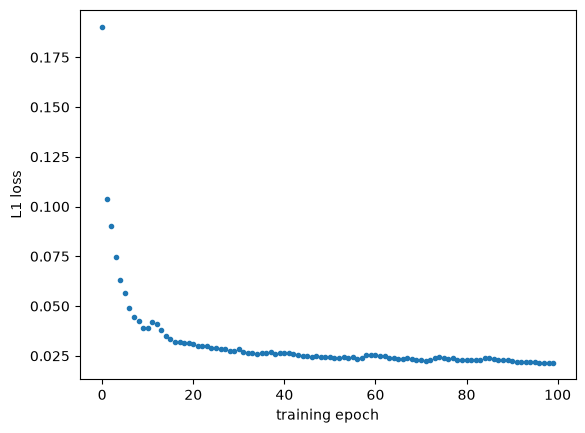

In [19]:
epochs = np.arange(0, training_epochs, step=1)
plt.plot(epochs, np.mean(loss_per_epoch, axis=1), '.')
plt.xlabel("training epoch")
plt.ylabel("L1 loss")
print(np.mean(loss_per_epoch, axis=1))

Text(0.5, 1.0, 'denoised image')

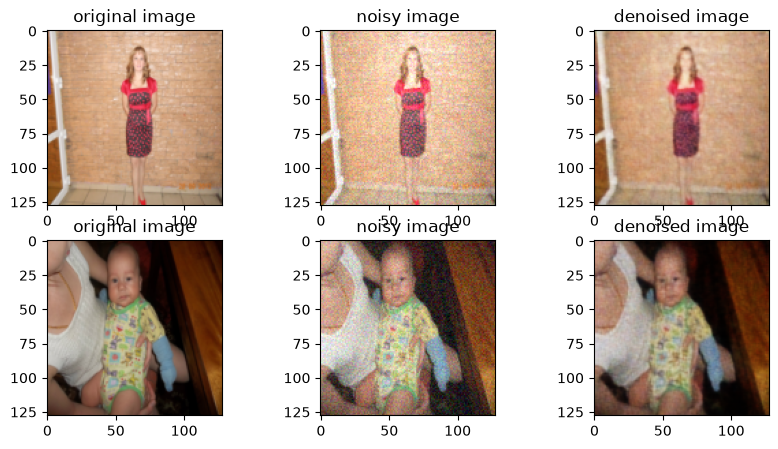

In [ ]:
indx = 12

train_x, train_y = training_loader.dataset[indx]
train_x = train_x.unsqueeze(0).to(device)
train_latent, train_denoised = model(train_x)


model.eval()
test_x, test_y = test_loader.dataset[indx]
test_x = test_x.unsqueeze(0).to(device)
test_latent, test_denoised = model(test_x)

fig, axes = plt.subplots(2, 3, figsize=(10, 5))

axes[0, 0].imshow(test_y.cpu().permute(1, 2, 0).clamp(0, 1))
axes[0, 1].imshow(test_x[0].detach().cpu().permute(1, 2, 0).clamp(0, 1))
axes[0, 2].imshow(test_denoised[0].detach().cpu().permute(1, 2, 0).clamp(0, 1))

axes[0, 0].set_title("original image")
axes[0, 1].set_title("noisy image")
axes[0, 2].set_title("denoised image")

axes[1, 0].imshow(train_y.cpu().permute(1, 2, 0).clamp(0, 1))
axes[1, 1].imshow(train_x[0].detach().cpu().permute(1, 2, 0).clamp(0, 1))
axes[1, 2].imshow(train_denoised[0].detach().cpu().permute(1, 2, 0).clamp(0, 1))

axes[1, 0].set_title("original image")
axes[1, 1].set_title("noisy image")
axes[1, 2].set_title("denoised image")





In [71]:
print(train_latent[0].shape)

torch.Size([256, 16, 16])


latent representation

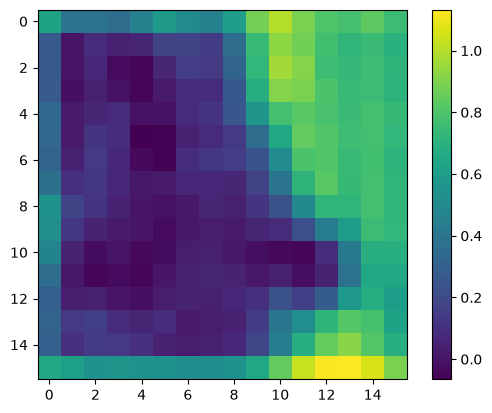

In [79]:
idx = 6
image = train_latent[0, idx] 
max_value = max( max(image[0]), max(image[1]))
min_value = min( min(image[0]), min(image[1]))
image = (image - min_value* torch.ones_like(image)) * 1/(max_value - min_value) 

plt.imshow(image.detach().numpy())
plt.colorbar()
plt.show()